### Notebook to use Rensenet50 Extractor for figurines.

In [2]:
#Importing necessary libraries
import os
import torch
import numpy as np
import pandas as pd
from PIL import Image
from torchvision import models, transforms
from tqdm.notebook import tqdm

# Importaciones para Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
# 1. Rutas de Entrada / Salida (Ajustadas para ResNet-50)
IMAGE_DIR = r"D:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\Dataset\Guerrero\Color\Decimated_1506\Sin_Fondo_2026-06-11\Cluster_34" #Your path from images
OUTPUT_DIR = r"D:\Luis\Tesis\IA\Codigo\Modelos\Classes\Bases\Dataset\Guerrero\Color\Decimated_1506\ResNet50_Features" #Your output path for features save
#CAM_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "Guerrero_New_Back_CAMs") 
Output_CSV_PATH = os.path.join(OUTPUT_DIR, "Cluster_34") #Name of the folder path

NPY_PATH = os.path.join(Output_CSV_PATH, "Cluster_34.npy") #Name of the file for Numpy
CSV_PATH = os.path.join(Output_CSV_PATH, "Cluster_34.csv") #Name of the file for CSV archive

os.makedirs(OUTPUT_DIR, exist_ok=True)
#os.makedirs(CAM_OUTPUT_DIR, exist_ok=True)
os.makedirs(Output_CSV_PATH, exist_ok=True)


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")

Using device: cpu


In [133]:
# 2. Definir el Modelo Preentrenado ResNet-50
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
model = model.to(DEVICE)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [135]:
from PIL import Image

def remove_alpha(img):
    if img.mode == 'RGBA':
        background = Image.new("RGB", img.size, (0,0,0))
        background.paste(img, mask=img.split()[3])
        return background
    return img.convert("RGB")

transform = transforms.Compose([
    transforms.Lambda(remove_alpha),
    transforms.Resize((512, 256)), # 256x128, 128x64
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def load_image_remove_alpha(path):
    img = Image.open(path)

    if img.mode == "RGBA":
        background = Image.new("RGB", img.size, (0, 0, 0))  # fondo negro
        background.paste(img, mask=img.split()[3])
        return background
    else:
        return img.convert("RGB")

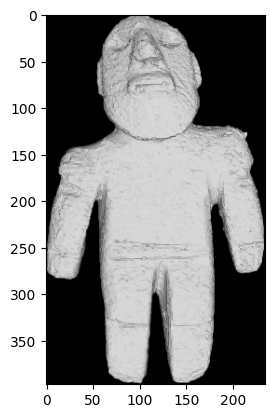

In [136]:
import matplotlib.pyplot as plt

file_name  = os.listdir(IMAGE_DIR)[0]
img_path = os.path.join(IMAGE_DIR, file_name)

    # Cargar imagen
img_pil = np.array(load_image_remove_alpha(img_path))

plt.imshow(img_pil)
plt.show()

In [ ]:
# 5. Bucle de Extracción
features = []
image_names = []

# Iteramos sobre las imágenes
for file_name in tqdm(sorted(os.listdir(IMAGE_DIR))):
    if not file_name.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    img_path = os.path.join(IMAGE_DIR, file_name)

    # Cargar imagen
    img_pil = load_image_remove_alpha(img_path)
    # img_pil = Image.open(img_path).convert("RGB")
    input_tensor = transform(img_pil).unsqueeze(0).to(DEVICE)

    # -- A. EXTRACCIÓN DE CARACTERÍSTICAS (2048 dimensiones) --
    # Replicamos el flujo de ResNet hasta la capa de pooling (antes del clasificador)
    with torch.no_grad():
        x = model.conv1(input_tensor)
        x = model.bn1(x)
        x = model.relu(x)
        x = model.maxpool(x)
        x = model.layer1(x)
        x = model.layer2(x)
        x = model.layer3(x)
        x = model.layer4(x)
        x = model.avgpool(x)
        
        # Aplanamos el tensor para obtener el vector 1D
        feature_vector = torch.flatten(x, 1).cpu().numpy().squeeze()
    
    features.append(feature_vector)
    image_names.append(file_name)


  0%|          | 0/3 [00:00<?, ?it/s]

In [ ]:
# 6. Guardar matrices finales
features = np.array(features)

np.save(NPY_PATH, features)
df = pd.DataFrame(features)
df.insert(0, "image_name", image_names)
df.to_csv(CSV_PATH, index=False)

print("¡Extracción y generación de mapas completadas con ResNet-50!")
#print(f"Mapas de calor guardados en: {CAM_OUTPUT_DIR}")
print(f"Forma de la matriz de características: {features.shape} (Debe ser N x 2048)")

¡Extracción y generación de mapas completadas con ResNet-50!
Forma de la matriz de características: (3, 2048) (Debe ser N x 2048)


: 